In [10]:
import kagglehub
import pandas as pd
import numpy as np
import os
import glob

def calculate_resting_durations(csv_path, n_minutes=1):
    """
    1分ごとの活動量データをN分に粗視化し、休息期の持続時間を算出する。
    """
    # データの読み込み
    df = pd.read_csv(csv_path)
    
    # タイムスタンプ列の自動検知と変換（データセットの仕様に合わせて適宜調整）
    # このデータセットは通常 'timestamp' 列を持ちます
    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        df.set_index('timestamp', inplace=True)
    
    # N分への粗視化
    rule = f'{n_minutes}min'
    # カラム名が 'activity' であると仮定
    df_resampled = df[['activity']].resample(rule).sum()
    df_resampled['activity'] = df_resampled['activity'].fillna(0)
    
    # 閾値の計算
    non_zero_activities = df_resampled[df_resampled['activity'] > 0]['activity']
    threshold = non_zero_activities.mean()
    
    # 休息期の判定と持続時間の計算
    df_resampled['is_resting'] = df_resampled['activity'] < threshold
    df_resampled['block_id'] = (df_resampled['is_resting'] != df_resampled['is_resting'].shift()).cumsum()
    
    resting_blocks = df_resampled[df_resampled['is_resting']]
    epoch_counts = resting_blocks.groupby('block_id').size()
    resting_durations_min = epoch_counts * n_minutes
    
    return resting_durations_min.values, threshold

if __name__ == "__main__":
    # image_b3dd07.png に記載されているコードでデータセットをダウンロード
    print("データセットをダウンロードしています...")
    path = kagglehub.dataset_download("nikitamanaenkov/psychiatric-motor-activity-dataset")
    print("ダウンロード先パス:", path)
    
    # このデータセットはルート直下に *-info.csv / features.csv（メタデータ、activity列なし）を持ち、
    # 実際の分刻み活動量データは adhd/ clinical/ control/ depression/ schizophrenia/ の
    # サブフォルダ内に被験者ごとのCSVとして格納されている。
    # そのため探索は1階層下のみに限定し、メタデータファイルを除外する。
    csv_files = glob.glob(os.path.join(path, '*', '*.csv'))
    
    if csv_files:
        # テストとして最初のファイルを使用（実際はループ等で全件処理します）
        target_csv = csv_files[0]
        print(f"\n解析対象ファイル: {target_csv}")
        
        # 1分（オリジナル）での解析
        durations_1m, thresh_1m = calculate_resting_durations(target_csv, n_minutes=1)
        # 5分に粗視化した場合の解析
        durations_5m, thresh_5m = calculate_resting_durations(target_csv, n_minutes=5)
        # 10分に粗視化した場合の解析
        durations_10m, thresh_10m = calculate_resting_durations(target_csv, n_minutes=10)
        
        print(f"1分粗視化 : 休息期エピソード数 = {len(durations_1m)}")
        print(f"5分粗視化 : 休息期エピソード数 = {len(durations_5m)}")
        print(f"10分粗視化: 休息期エピソード数 = {len(durations_10m)}")
    else:
        print("CSVファイルが見つかりませんでした。")

データセットをダウンロードしています...
ダウンロード先パス: /Users/nkn4ryu/.cache/kagglehub/datasets/nikitamanaenkov/psychiatric-motor-activity-dataset/versions/1

解析対象ファイル: /Users/nkn4ryu/.cache/kagglehub/datasets/nikitamanaenkov/psychiatric-motor-activity-dataset/versions/1/schizophrenia/schizophrenia_13.csv
1分粗視化 : 休息期エピソード数 = 1418
5分粗視化 : 休息期エピソード数 = 340
10分粗視化: 休息期エピソード数 = 187


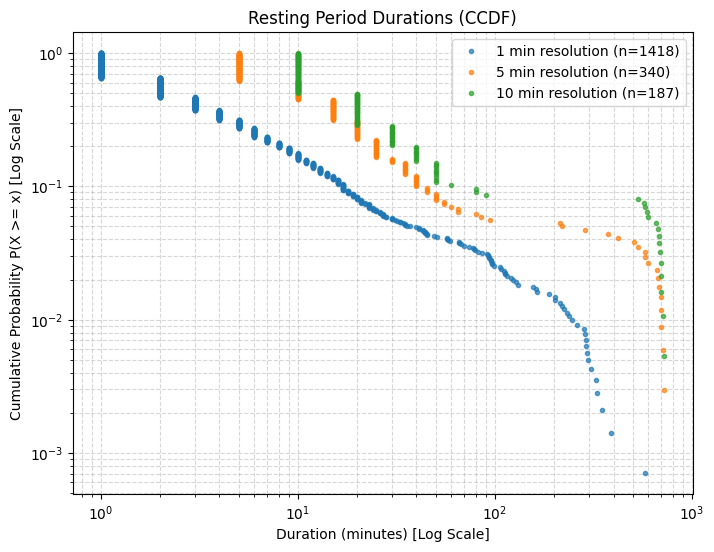

In [11]:
import matplotlib.pyplot as plt

def plot_ccdf(durations_list, labels, title="Resting Period Durations (CCDF)"):
    """
    抽出した持続時間のリストから、相補累積分布関数(CCDF)を両対数グラフでプロットする。
    """
    plt.figure(figsize=(8, 6))
    
    for durations, label in zip(durations_list, labels):
        if len(durations) == 0:
            continue
            
        # データを昇順にソート
        sorted_data = np.sort(durations)
        
        # 累積確率 P(X >= x) を計算
        # 1.0から始まり、データ数に応じて減少していく
        p = 1.0 - np.arange(1, len(sorted_data) + 1) / len(sorted_data)
        
        # p=0 になると対数グラフでエラーになるため、最後の要素を除外
        sorted_data = sorted_data[:-1]
        p = p[:-1]
        
        # 両対数プロット（Log-Logプロット）
        plt.loglog(sorted_data, p, marker='.', linestyle='none', label=f"{label} (n={len(durations)})", alpha=0.7)
        
    plt.xlabel("Duration (minutes) [Log Scale]")
    plt.ylabel("Cumulative Probability P(X >= x) [Log Scale]")
    plt.title(title)
    plt.legend()
    plt.grid(True, which="both", ls="--", alpha=0.5)
    plt.show()

# ======== 先ほどの if __name__ == "__main__": の末尾に追加 ========
# グラフの描画
plot_ccdf(
    [durations_1m, durations_5m, durations_10m],
    ["1 min resolution", "5 min resolution", "10 min resolution"]
)


--- 1 分 分解能 (Resolution: 1 min) ---
Control スケーリング指数 γ: 0.848
Depression スケーリング指数 γ: 0.803


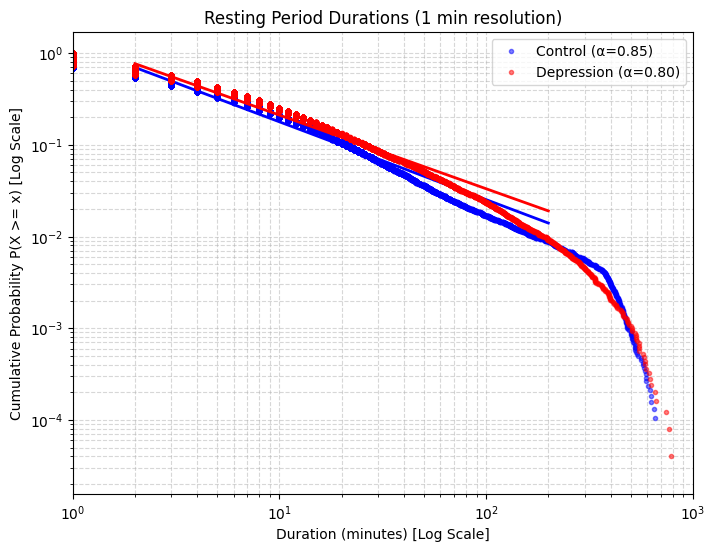


--- 5 分 分解能 (Resolution: 5 min) ---
Control スケーリング指数 γ: 0.765
Depression スケーリング指数 γ: 0.721


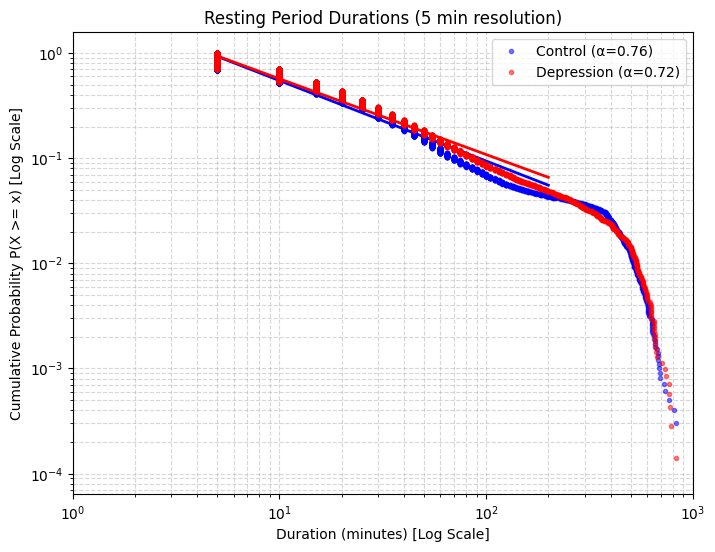


--- 10 分 分解能 (Resolution: 10 min) ---
Control スケーリング指数 γ: 0.770
Depression スケーリング指数 γ: 0.717


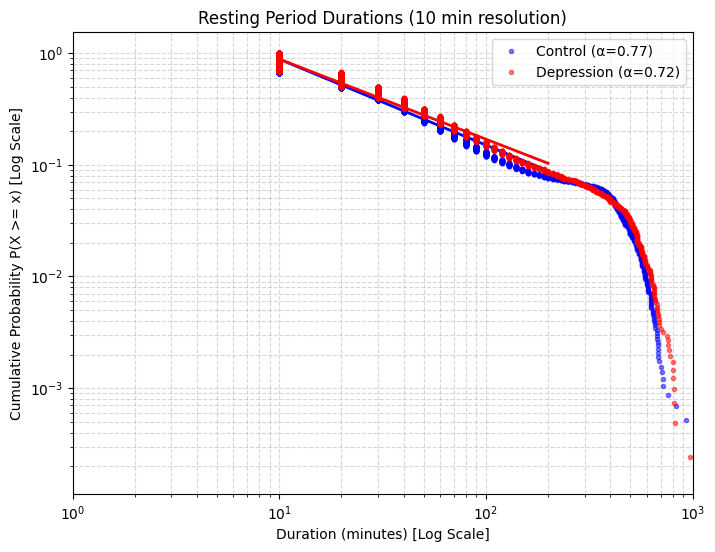


--- 30 分 分解能 (Resolution: 30 min) ---
Control スケーリング指数 γ: 0.727
Depression スケーリング指数 γ: 0.674


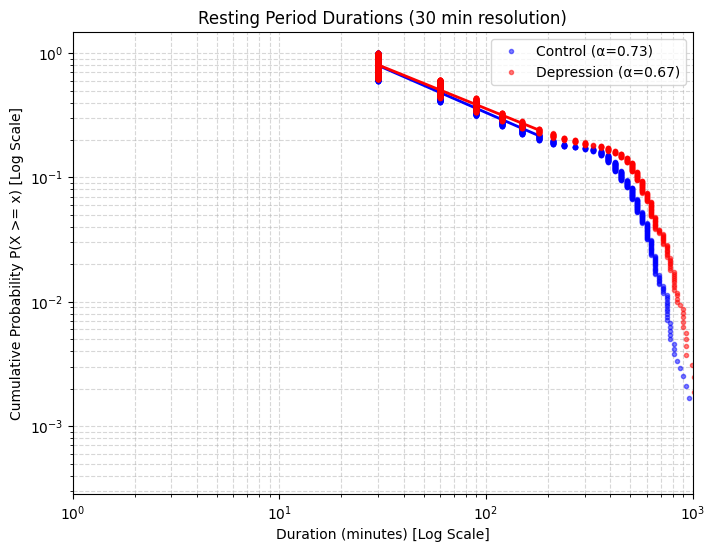


--- 60 分 分解能 (Resolution: 60 min) ---
Control スケーリング指数 γ: 0.620
Depression スケーリング指数 γ: 0.534


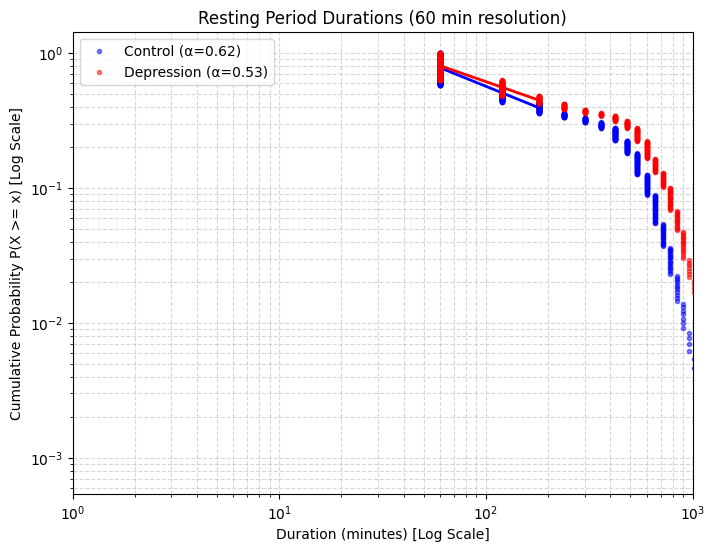


--- 100 分 分解能 (Resolution: 100 min) ---
Control スケーリング指数 γ: 0.453
Depression スケーリング指数 γ: 0.407


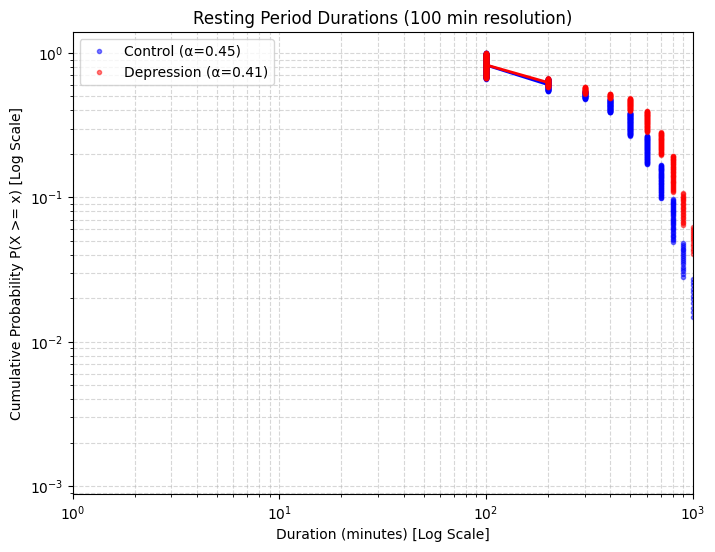

In [15]:
import kagglehub
import pandas as pd
import numpy as np
import os
import glob
import matplotlib.pyplot as plt
from scipy.stats import linregress

def calculate_resting_durations(csv_path, n_minutes=1, max_days=None):
    """1ファイルからN分粗視化における休息期の持続時間を抽出する。

    max_daysを指定すると、記録開始タイムスタンプから max_days 日分だけを解析対象にする。
    *-info.csvのdays列（公式な研究対象期間）に合わせてトリミングするために使う。
    """
    df = pd.read_csv(csv_path)
    if 'timestamp' in df.columns:
        df['timestamp'] = pd.to_datetime(df['timestamp'])
        df.set_index('timestamp', inplace=True)

    if max_days is not None:
        cutoff = df.index.min() + pd.Timedelta(days=max_days)
        df = df[df.index < cutoff]

    rule = f'{n_minutes}min'
    df_resampled = df[['activity']].resample(rule).sum()
    df_resampled['activity'] = df_resampled['activity'].fillna(0)
    
    non_zero_activities = df_resampled[df_resampled['activity'] > 0]['activity']
    if len(non_zero_activities) == 0:
        return np.array([])
        
    threshold = non_zero_activities.mean()
    
    df_resampled['is_resting'] = df_resampled['activity'] < threshold
    df_resampled['block_id'] = (df_resampled['is_resting'] != df_resampled['is_resting'].shift()).cumsum()
    
    resting_blocks = df_resampled[df_resampled['is_resting']]
    epoch_counts = resting_blocks.groupby('block_id').size()
    return (epoch_counts * n_minutes).values

def get_group_durations(folder_path, n_minutes=1, info_df=None):
    """フォルダ内の全被験者の休息期データを結合する。

    info_df（numberをインデックスにしたdays列を持つDataFrame）を渡すと、
    各被験者を記録開始からdays日分にトリミングしてから抽出する。
    """
    all_durations = []
    csv_files = glob.glob(os.path.join(folder_path, '*.csv'))
    for file in csv_files:
        max_days = None
        if info_df is not None:
            subject_id = os.path.splitext(os.path.basename(file))[0]
            if subject_id in info_df.index:
                max_days = info_df.loc[subject_id, 'days']
        durations = calculate_resting_durations(file, n_minutes, max_days=max_days)
        all_durations.extend(durations)
    return np.array(all_durations)

def estimate_scaling_exponent(durations, min_val=2, max_val=200):
    """
    論文に準拠し、CCDFの両対数プロットに対して線形回帰を行い、
    スケーリング指数 γ を推定する。
    """
    if len(durations) < 10:
        return np.nan, None

    sorted_data = np.sort(durations)
    p = 1.0 - np.arange(1, len(sorted_data) + 1) / len(sorted_data)
    
    # 確率0を対数変換から除外
    sorted_data = sorted_data[:-1]
    p = p[:-1]
    
    # 論文に基づくフィッティング範囲（2分〜200分）の抽出
    mask = (sorted_data >= min_val) & (sorted_data <= max_val)
    x_fit = np.log10(sorted_data[mask])
    y_fit = np.log10(p[mask])
    
    if len(x_fit) < 2:
        return np.nan, None

    # 線形回帰 (y = -gamma * x + intercept)
    slope, intercept, r_value, p_value, std_err = linregress(x_fit, y_fit)
    
    # スケーリング指数は傾きのマイナス値
    gamma = -slope
    return gamma, (sorted_data[mask], 10**(slope * x_fit + intercept))

# ==========================================
# 実行と可視化
# ==========================================
if __name__ == "__main__":
    # kagglehubのキャッシュ済みダウンロード先を再取得（未取得の場合はダウンロードされる）
    dataset_path = kagglehub.dataset_download("nikitamanaenkov/psychiatric-motor-activity-dataset")
    control_dir = os.path.join(dataset_path, "control")
    depression_dir = os.path.join(dataset_path, "depression")

    # 各被験者の公式な研究対象期間（days）を取得し、
    # CSV全体ではなく記録開始からdays日分だけを解析に使う
    control_info = pd.read_csv(os.path.join(dataset_path, "control-info.csv")).set_index("number")
    depression_info = pd.read_csv(os.path.join(dataset_path, "depression-info.csv")).set_index("number")

    resolutions = [1, 5, 10,30,60,100]
    
    for res in resolutions:
        print(f"\n--- {res} 分 分解能 (Resolution: {res} min) ---")
        
        # データの抽出と結合
        ctrl_dur = get_group_durations(control_dir, n_minutes=res, info_df=control_info)
        dep_dur = get_group_durations(depression_dir, n_minutes=res, info_df=depression_info)
        
        # ガンマの計算 (2〜200分の範囲)
        ctrl_gamma, ctrl_fit = estimate_scaling_exponent(ctrl_dur, min_val=2, max_val=200)
        dep_gamma, dep_fit = estimate_scaling_exponent(dep_dur, min_val=2, max_val=200)
        
        print(f"Control スケーリング指数 γ: {ctrl_gamma:.3f}")
        print(f"Depression スケーリング指数 γ: {dep_gamma:.3f}")
        
        # グラフの描画
        plt.figure(figsize=(8, 6))
        
        # 健常者のプロットと回帰線
        if len(ctrl_dur) > 0:
            ctrl_sorted = np.sort(ctrl_dur)[:-1]
            ctrl_p = (1.0 - np.arange(1, len(ctrl_dur)) / len(ctrl_dur))
            plt.loglog(ctrl_sorted, ctrl_p, '.', label=f"Control (α={ctrl_gamma:.2f})", color='blue', alpha=0.5)
            if ctrl_fit is not None:
                plt.loglog(ctrl_fit[0], ctrl_fit[1], 'b-', linewidth=2)
                
        # うつ病患者のプロットと回帰線
        if len(dep_dur) > 0:
            dep_sorted = np.sort(dep_dur)[:-1]
            dep_p = (1.0 - np.arange(1, len(dep_dur)) / len(dep_dur))
            plt.loglog(dep_sorted, dep_p, '.', label=f"Depression (α={dep_gamma:.2f})", color='red', alpha=0.5)
            if dep_fit is not None:
                plt.loglog(dep_fit[0], dep_fit[1], 'r-', linewidth=2)
        
        plt.xlabel("Duration (minutes) [Log Scale]")
        plt.ylabel("Cumulative Probability P(X >= x) [Log Scale]")
        plt.title(f"Resting Period Durations ({res} min resolution)")
        plt.legend()
        plt.grid(True, which="both", ls="--", alpha=0.5)
        plt.xlim(1, 1000)
        plt.show()